In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import xgboost as xgb

RANDOM_STATE = 42
DATA_DIR = "data"
RUL_CAP = 125  # piecewise-linear RUL cap — engines are "healthy" (flat RUL) above this

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
np.random.seed(RANDOM_STATE)

In [148]:
import os
import pandas as pd
import numpy as np

DATA_DIR = "data"

print("Current notebook folder:", os.getcwd())
print("Data folder exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Files inside data/:")
    print(os.listdir(DATA_DIR))

COLS = (
    ["unit", "cycle", "op1", "op2", "op3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

def load_cmapss(path):
    print("Trying to load:", path)
    print("File exists:", os.path.exists(path))
    
    df = pd.read_csv(
        path,
        sep=r"\s+",
        header=None,
        names=COLS
    )
    
    return df

train = load_cmapss(f"{DATA_DIR}/train_FD001.txt")
test = load_cmapss(f"{DATA_DIR}/test_FD001.txt")

test_rul = pd.read_csv(
    f"{DATA_DIR}/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("\nTrain shape:", train.shape)
print("Test shape:", test.shape)
print("Test RUL shape:", test_rul.shape)

display(train.head())

Current notebook folder: C:\Users\OMEN\project
Data folder exists: True
Files inside data/:
['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']
Trying to load: data/train_FD001.txt
File exists: True
Trying to load: data/test_FD001.txt
File exists: True

Train shape: (20631, 26)
Test shape: (13096, 26)
Test RUL shape: (100, 1)


,unit,cycle,op1,op2,op3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [149]:
print("Train shape:", train.shape)
print("Columns:", train.columns.tolist())
print(train.head())

Train shape: (20631, 26)
Columns: ['unit', 'cycle', 'op1', 'op2', 'op3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
   unit  cycle     op1     op2    op3  sensor_1  sensor_2  sensor_3  sensor_4  \
0     1      1 -0.0007 -0.0004  100.0    518.67    641.82   1589.70   1400.60   
1     1      2  0.0019 -0.0003  100.0    518.67    642.15   1591.82   1403.14   
2     1      3 -0.0043  0.0003  100.0    518.67    642.35   1587.99   1404.20   
3     1      4  0.0007  0.0000  100.0    518.67    642.35   1582.79   1401.87   
4     1      5 -0.0019 -0.0002  100.0    518.67    642.37   1582.85   1406.22   

   sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  \
0     14.62     21.61    554.36   2388.06   9046.19        1.3      47.47   
1     14.62     21.61 

After RUL calculation: (20631, 27)
RUL_CAP: 125
RUL missing: 0


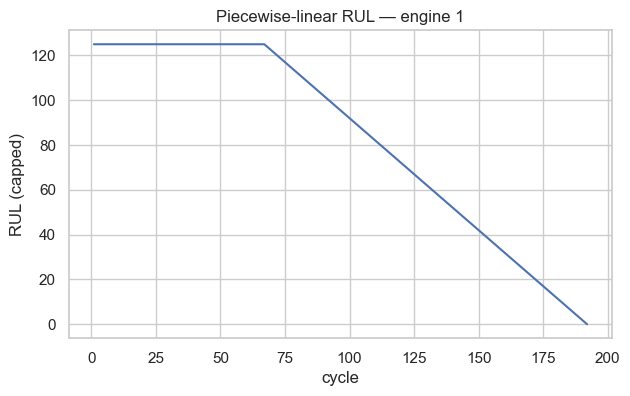

In [150]:
def add_rul_train(df, cap=RUL_CAP):
    df = df.copy()

    max_cycle = df.groupby("unit")["cycle"].transform("max")

    df["RUL"] = max_cycle - df["cycle"]

    df["RUL"] = df["RUL"].clip(upper=cap)

    return df


train = add_rul_train(train)

print("After RUL calculation:", train.shape)
print("RUL_CAP:", RUL_CAP)
print("RUL missing:", train["RUL"].isna().sum())

sample_unit = train["unit"].unique()[0]

sub = train[train["unit"] == sample_unit]

plt.figure(figsize=(7, 4))
plt.plot(sub["cycle"], sub["RUL"])
plt.title(f"Piecewise-linear RUL — engine {sample_unit}")
plt.xlabel("cycle")
plt.ylabel("RUL (capped)")
plt.show()


In [151]:
# 3.1 — near-constant sensors (candidates to drop)
sensor_cols = [c for c in train.columns if c.startswith("sensor_")]
variances = train[sensor_cols].std().sort_values()
print("Lowest-variance sensors:")
print(variances.head(10))

low_var_sensors = variances[variances < 1e-3].index.tolist()
print("\nDrop candidates (near-constant):", low_var_sensors)


Lowest-variance sensors:
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
dtype: float64

Drop candidates (near-constant): ['sensor_19', 'sensor_18', 'sensor_16', 'sensor_10', 'sensor_5', 'sensor_1']


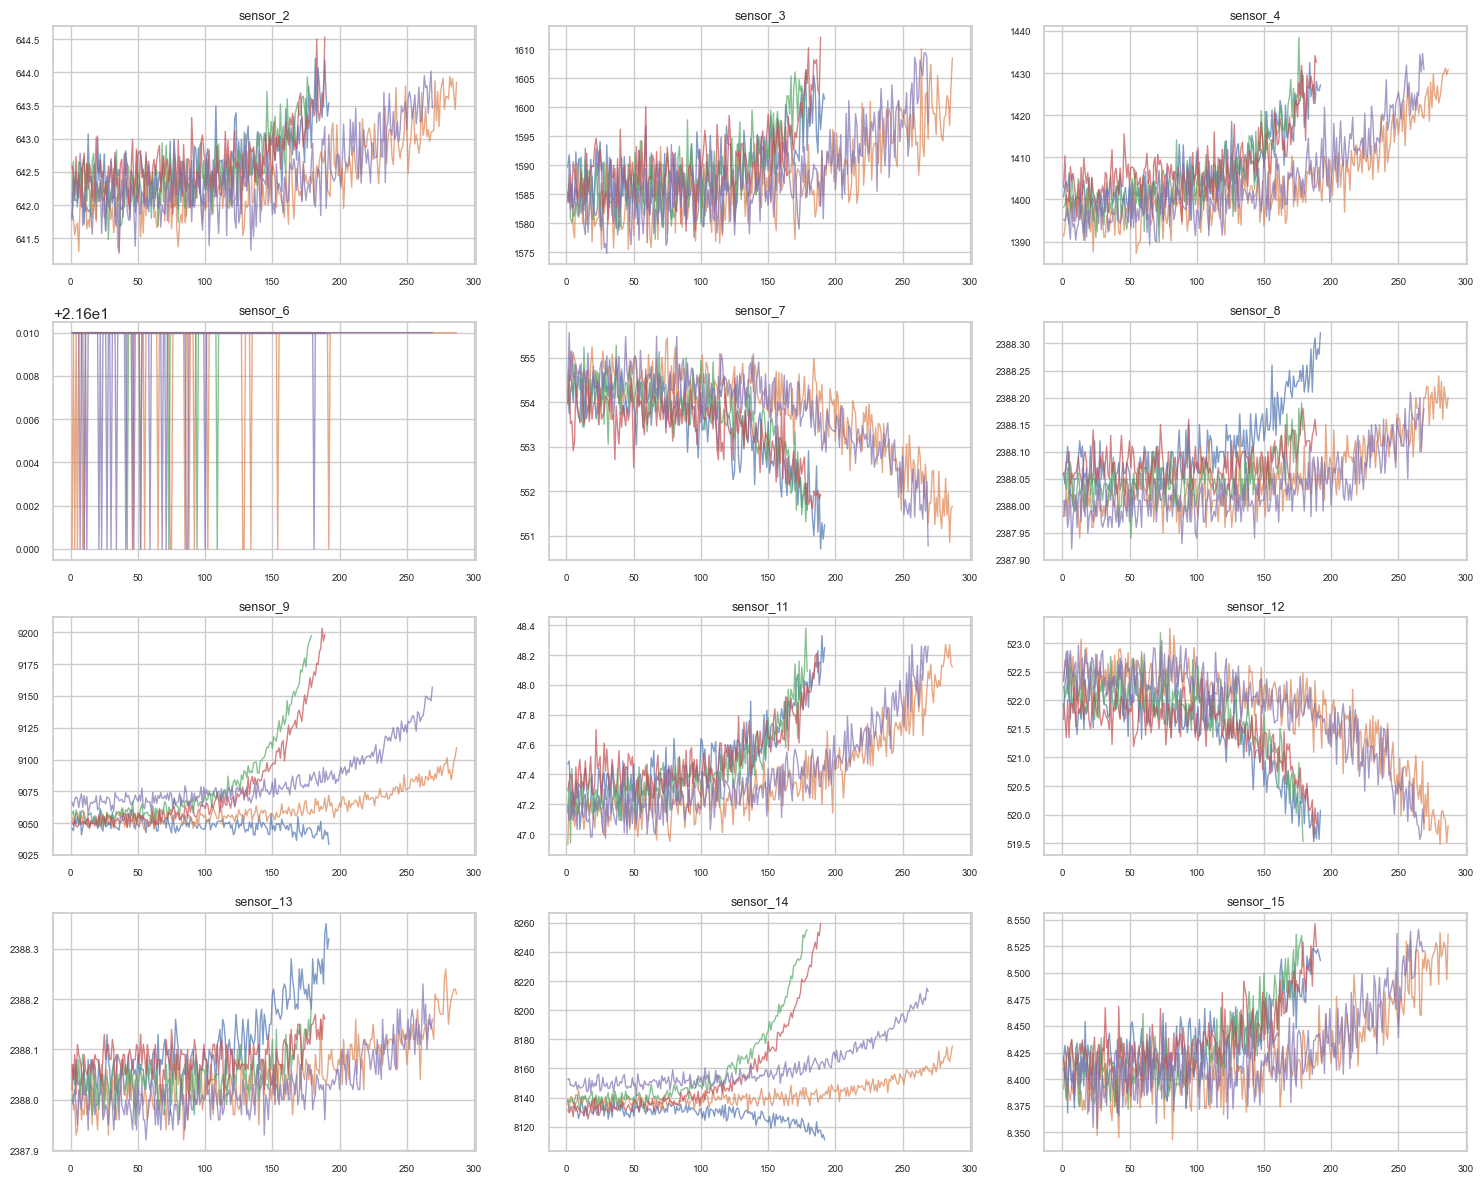

In [152]:
# 3.2 — sensor trends across life for a handful of engines
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
plot_sensors = [c for c in sensor_cols if c not in low_var_sensors][:12]
sample_units = train["unit"].unique()[:5]

for ax, sensor in zip(axes.flat, plot_sensors):
    for u in sample_units:
        sub = train[train["unit"] == u]
        ax.plot(sub["cycle"], sub[sensor], alpha=0.7, linewidth=1)
    ax.set_title(sensor, fontsize=9)
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()


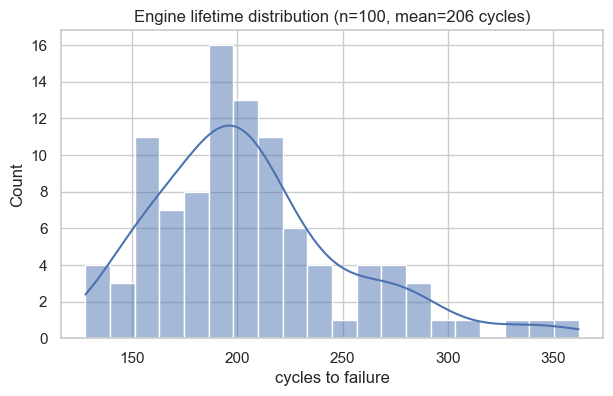

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [153]:
# 3.3 — engine lifetime distribution
lifetimes = train.groupby("unit")["cycle"].max()
plt.figure(figsize=(7, 4))
sns.histplot(lifetimes, bins=20, kde=True)
plt.title(f"Engine lifetime distribution (n={len(lifetimes)}, mean={lifetimes.mean():.0f} cycles)")
plt.xlabel("cycles to failure")
plt.show()

lifetimes.describe()


In [154]:
FEATURE_SENSORS = [c for c in sensor_cols if c not in low_var_sensors]
ROLL_WINDOW = 5
LAG = 5

def engineer_features(df, sensors=FEATURE_SENSORS, window=ROLL_WINDOW, lag=LAG):
    df = df.sort_values(["unit", "cycle"]).copy()
    g = df.groupby("unit")

    for s in sensors:
        df[f"{s}_roll_mean"] = g[s].transform(lambda x: x.rolling(window, min_periods=1).mean())
        df[f"{s}_roll_std"] = g[s].transform(lambda x: x.rolling(window, min_periods=1).std().fillna(0))
        df[f"{s}_diff"] = g[s].transform(lambda x: x.diff(lag).fillna(0))

    return df

train_fe = engineer_features(train)
test_fe = engineer_features(test)

feature_cols = (
    FEATURE_SENSORS
    + [f"{s}_roll_mean" for s in FEATURE_SENSORS]
    + [f"{s}_roll_std" for s in FEATURE_SENSORS]
    + [f"{s}_diff" for s in FEATURE_SENSORS]
    + ["op1", "op2", "op3"]
)
print(f"{len(feature_cols)} features")
train_fe[feature_cols].head()


63 features


,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,sensor_2_roll_mean,sensor_3_roll_mean,sensor_4_roll_mean,sensor_6_roll_mean,sensor_7_roll_mean,sensor_8_roll_mean,sensor_9_roll_mean,sensor_11_roll_mean,sensor_12_roll_mean,sensor_13_roll_mean,...,sensor_12_roll_std,sensor_13_roll_std,sensor_14_roll_std,sensor_15_roll_std,sensor_17_roll_std,sensor_20_roll_std,sensor_21_roll_std,sensor_2_diff,sensor_3_diff,sensor_4_diff,sensor_6_diff,sensor_7_diff,sensor_8_diff,sensor_9_diff,sensor_11_diff,sensor_12_diff,sensor_13_diff,sensor_14_diff,sensor_15_diff,sensor_17_diff,sensor_20_diff,sensor_21_diff,op1,op2,op3
0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,641.820000,1589.700000,1400.600000,21.61,554.360000,2388.0600,9046.190000,47.470,521.660,2388.020,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0007,-0.0004,100.0
1,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,641.985000,1590.760000,1401.870000,21.61,554.055000,2388.0500,9045.130000,47.480,521.970,2388.045,...,0.438406,0.035355,5.041671,0.008697,0.000000,0.042426,0.003253,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0019,-0.0003,100.0
2,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,642.106667,1589.836667,1402.646667,21.61,554.123333,2388.0600,9047.733333,47.410,522.120,2388.040,...,0.404475,0.026458,3.717450,0.007640,1.154701,0.055076,0.044573,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0043,0.0003,100.0
3,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,642.167500,1588.075000,1402.452500,21.61,554.205000,2388.0725,9048.170000,47.340,522.305,2388.050,...,0.495950,0.029439,3.050906,0.028117,1.000000,0.076322,0.037977,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0007,0.0000,100.0
4,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,642.208000,1587.030000,1403.206000,21.61,554.164000,2388.0700,9049.566000,47.328,522.282,2388.048,...,0.432574,0.025884,2.651326,0.025953,1.095445,0.073621,0.033498,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0019,-0.0002,100.0


In [155]:
from sklearn.model_selection import train_test_split

all_units = train_fe["unit"].unique()
train_units, val_units = train_test_split(all_units, test_size=0.2, random_state=RANDOM_STATE)

X_train = train_fe[train_fe["unit"].isin(train_units)][feature_cols]
y_train = train_fe[train_fe["unit"].isin(train_units)]["RUL"]

X_val = train_fe[train_fe["unit"].isin(val_units)][feature_cols]
y_val = train_fe[train_fe["unit"].isin(val_units)]["RUL"]

print(f"train: {len(train_units)} engines / {len(X_train)} rows")
print(f"val:   {len(val_units)} engines / {len(X_val)} rows")

# Test set: last cycle per engine, labeled by RUL_FD001.txt
test_last = test_fe.groupby("unit").last().reset_index()
X_test = test_last[feature_cols]
y_test = test_rul["RUL"].clip(upper=RUL_CAP).values
print(f"test:  {test_last['unit'].nunique()} engines (last cycle each)")


train: 80 engines / 16561 rows
val:   20 engines / 4070 rows
test:  100 engines (last cycle each)


In [156]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

def evaluate(model, X, y, label):
    pred = model.predict(X)
    mae = mean_absolute_error(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))
    r2 = r2_score(y, pred)
    print(f"[{label}]  MAE={mae:6.2f}  RMSE={rmse:6.2f}  R2={r2:.3f}")
    return pred, {"MAE": mae, "RMSE": rmse, "R2": r2}

_, rf_val_metrics = evaluate(rf, X_val, y_val, "RF - val")
rf_test_pred, rf_test_metrics = evaluate(rf, X_test, y_test, "RF - test")


[RF - val]  MAE= 11.51  RMSE= 16.38  R2=0.846
[RF - test]  MAE= 12.37  RMSE= 17.80  R2=0.803


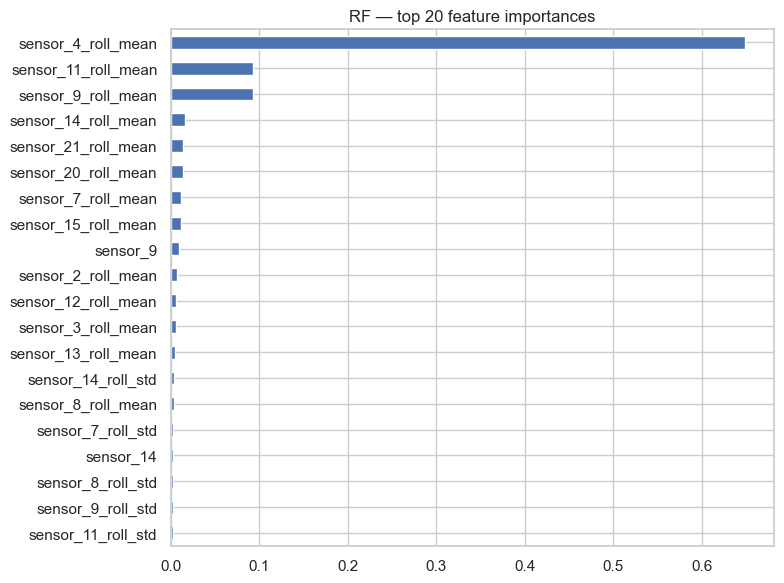

In [157]:
# RF feature importance — quick sanity check that engineered features matter
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances.head(20).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("RF — top 20 feature importances")
plt.tight_layout()
plt.show()


In [158]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    early_stopping_rounds=30,
    eval_metric="mae",
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

print("best iteration:", xgb_model.best_iteration)
_, xgb_val_metrics = evaluate(xgb_model, X_val, y_val, "XGB - val")
xgb_test_pred, xgb_test_metrics = evaluate(xgb_model, X_test, y_test, "XGB - test")


best iteration: 237
[XGB - val]  MAE= 11.38  RMSE= 16.13  R2=0.850
[XGB - test]  MAE= 12.18  RMSE= 17.34  R2=0.813


In [159]:
comparison = pd.DataFrame({
    "RF":  {**rf_val_metrics, **{f"test_{k}": v for k, v in rf_test_metrics.items()}},
    "XGB": {**xgb_val_metrics, **{f"test_{k}": v for k, v in xgb_test_metrics.items()}},
}).T
comparison


,MAE,RMSE,R2,test_MAE,test_RMSE,test_R2
RF,11.510183,16.378001,0.845857,12.373248,17.804117,0.802607
XGB,11.378615,16.129797,0.850494,12.175119,17.344147,0.812675


In [160]:
# Get the unique test engine IDs in the same order as test_fe

test_units = test_fe["unit"].drop_duplicates().values

print("Number of test units:", len(test_units))
print("Number of RF predictions:", len(rf_test_pred))
print("Number of XGB predictions:", len(xgb_test_pred))

Number of test units: 100
Number of RF predictions: 100
Number of XGB predictions: 100


In [161]:
engine_uncertainty = pd.DataFrame({
    "unit": test_units,
    "uncertainty": np.abs(
        rf_test_pred - xgb_test_pred
    )
})

print("Uncertainty proxy statistics:")
print(engine_uncertainty["uncertainty"].describe())

display(engine_uncertainty.head())

Uncertainty proxy statistics:
count    100.000000
mean       2.435897
std        2.156789
min        0.009083
25%        0.937238
50%        1.735343
75%        3.386976
max       11.202102
Name: uncertainty, dtype: float64


,unit,uncertainty
0,1,1.310654
1,2,0.918492
2,3,0.281128
3,4,0.336685
4,5,2.938679


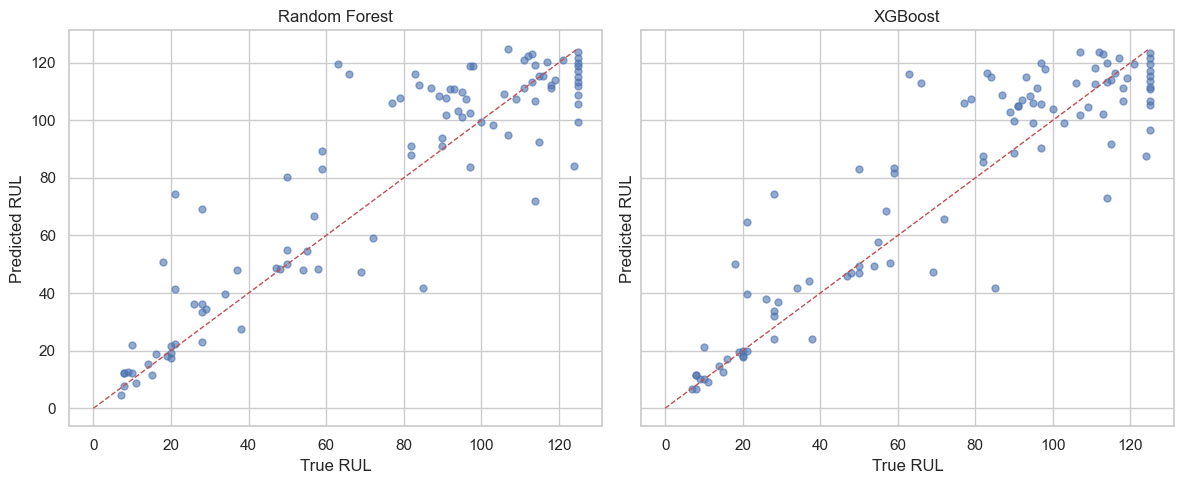

Winner on validation R²: XGB


In [162]:
# Predicted vs actual RUL — visual check on test engines
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, pred, name in zip(axes, [rf_test_pred, xgb_test_pred], ["Random Forest", "XGBoost"]):
    ax.scatter(y_test, pred, alpha=0.6, s=25)
    lims = [0, RUL_CAP]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel("True RUL"); ax.set_ylabel("Predicted RUL")
    ax.set_title(name)
plt.tight_layout()
plt.show()

winner = "XGB" if xgb_val_metrics["R2"] >= rf_val_metrics["R2"] else "RF"
winner_model = xgb_model if winner == "XGB" else rf

print(f"Winner on validation R²: {winner}")


In [163]:
# Predict RUL for every row (not just last cycle) so the health-score stage
# can show a trajectory, not just a single point, per engine.
train_fe["RUL_pred"] = winner_model.predict(train_fe[feature_cols])
test_fe["RUL_pred"] = winner_model.predict(test_fe[feature_cols])

out_cols = ["unit", "cycle", "RUL_pred"]
train_out = train_fe[out_cols + ["RUL"]].rename(columns={"RUL": "RUL_true"})
test_out = test_fe[out_cols].copy()
test_out["RUL_true"] = np.nan  # unknown until last cycle; last-cycle RUL filled in below
last_idx = test_out.groupby("unit")["cycle"].idxmax()
test_out.loc[last_idx, "RUL_true"] = test_rul["RUL"].clip(upper=RUL_CAP).values

predictions = pd.concat([train_out, test_out], ignore_index=True)

predictions = predictions[["unit", "cycle", "RUL_pred", "RUL_true"]]

predictions.to_csv("predictions.csv", index=False)

print("Saved predictions.csv")
print("Columns:", predictions.columns.tolist())
print("Shape:", predictions.shape)

display(predictions.head())


Saved predictions.csv
Columns: ['unit', 'cycle', 'RUL_pred', 'RUL_true']
Shape: (33727, 4)


,unit,cycle,RUL_pred,RUL_true
0,1,1,124.983704,125.0
1,1,2,121.462219,125.0
2,1,3,123.621719,125.0
3,1,4,124.400780,125.0
4,1,5,123.339729,125.0


SHAP + Health/Risk Score

In [164]:
!pip install shap

In [165]:
import shap
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(test_fe[feature_cols])
print("SHAP shape:",shap_values.shape)

SHAP shape: (13096, 63)


In [166]:
def rul_to_risk(rul):
    risk = ((RUL_CAP - rul)/RUL_CAP) * 100
    return np.clip(risk,0,100)

test_risk = rul_to_risk(test_fe["RUL_pred"].values)
print("Risk range:",test_risk.min(),"to",test_risk.max())

Risk range: 0.0 to 94.749344


In [167]:
top_features = []

for i in range(len(shap_values)):
    importance = np.abs(shap_values[i])
    
    top_idx = np.argsort(importance)[-3:][::-1]
    
    top_features.append([
        feature_cols[top_idx[0]],
        feature_cols[top_idx[1]],
        feature_cols[top_idx[2]]
    ])

top_features = np.array(top_features)

print(top_features[:5])

[['sensor_4_roll_mean' 'sensor_11_roll_mean' 'sensor_9_roll_mean']
 ['sensor_4_roll_mean' 'sensor_11_roll_mean' 'sensor_9_roll_mean']
 ['sensor_4_roll_mean' 'sensor_11_roll_mean' 'sensor_14_roll_std']
 ['sensor_4_roll_mean' 'sensor_11_roll_mean' 'sensor_9_roll_mean']
 ['sensor_4_roll_mean' 'sensor_11_roll_mean' 'sensor_9_roll_mean']]


In [168]:
risk_output = test_fe[["unit", "cycle"]].copy()

risk_output["RUL_pred"] = test_fe["RUL_pred"].values
risk_output["risk_score"] = test_risk

risk_output["top_feature_1"] = top_features[:, 0]
risk_output["top_feature_2"] = top_features[:, 1]
risk_output["top_feature_3"] = top_features[:, 2]

display(risk_output.head())

,unit,cycle,RUL_pred,risk_score,top_feature_1,top_feature_2,top_feature_3
0,1,1,129.330719,0.000000,sensor_4_roll_mean,sensor_11_roll_mean,sensor_9_roll_mean
1,1,2,122.775185,1.779852,sensor_4_roll_mean,sensor_11_roll_mean,sensor_9_roll_mean
2,1,3,119.056755,4.754596,sensor_4_roll_mean,sensor_11_roll_mean,sensor_14_roll_std
3,1,4,121.354561,2.916351,sensor_4_roll_mean,sensor_11_roll_mean,sensor_9_roll_mean
4,1,5,122.690544,1.847565,sensor_4_roll_mean,sensor_11_roll_mean,sensor_9_roll_mean


In [169]:
risk_output.to_csv("risk_explanations.csv", index=False)

print("Saved risk_explanations.csv")
print("Shape:", risk_output.shape)

Saved risk_explanations.csv
Shape: (13096, 7)


Corrosion Proxy

In [170]:
print(test_fe[feature_cols].describe().T)

                  count         mean       std        min        25%  \
sensor_2        13096.0   642.475088  0.400899   641.1300   642.1975   
sensor_3        13096.0  1588.099204  5.003274  1569.0400  1584.6000   
sensor_4        13096.0  1404.735362  6.688309  1384.3900  1399.9500   
sensor_6        13096.0    21.609701  0.001704    21.6000    21.6100   
sensor_7        13096.0   553.757523  0.681286   550.8800   553.3100   
...                 ...          ...       ...        ...        ...   
sensor_20_diff  13096.0    -0.006354  0.140281    -0.7100    -0.1000   
sensor_21_diff  13096.0    -0.003427  0.083149    -0.3729    -0.0583   
op1             13096.0    -0.000011  0.002203    -0.0082    -0.0015   
op2             13096.0     0.000004  0.000294    -0.0006    -0.0002   
op3             13096.0   100.000000  0.000000   100.0000   100.0000   

                      50%        75%        max  
sensor_2         642.4600   642.7400   644.3000  
sensor_3        1587.9900  1591.362

In [171]:
def calculate_corrosion_proxy(df):
    """
    Illustrative corrosion proxy.
    NOT a trained or physically calibrated corrosion model.

    Uses:
    - sensor_4: operating-condition/stress proxy
    - sensor_11: operating-condition/stress proxy
    - cycle: time-in-service proxy
    """
# The bounds below are manually selected from the observed ranges
# of these C-MAPSS sensors to create normalized low/high stress proxies.
# They are illustrative thresholds only and are NOT physical corrosion
# limits or calibrated engineering values.        
    stress_1 = np.clip(
        (df["sensor_4"] - 1384) / (1410 - 1384),
        0, 1
    )

    stress_2 = np.clip(
        (df["sensor_11"] - 45) / (50 - 45),
        0, 1
    )

    time_factor = np.clip(
        df["cycle"] / df["cycle"].max(),
        0, 1
    )

    corrosion = (
        0.4 * stress_1 +
        0.3 * stress_2 +
        0.3 * time_factor
    ) * 100

    return np.clip(corrosion, 0, 100)

In [172]:
test_fe["corrosion_score"] = calculate_corrosion_proxy(test_fe)

print(test_fe["corrosion_score"].describe())

count    13096.000000
mean        52.636199
std         11.937310
min         14.442087
25%         43.786756
50%         52.650274
75%         61.396950
max         88.060000
Name: corrosion_score, dtype: float64


In [173]:
display(
    test_fe[
        ["unit", "cycle", "corrosion_score"]
    ].head(10)
)

,unit,cycle,corrosion_score
0,1,1,35.160548
1,1,2,32.767251
2,1,3,41.973953
3,1,4,48.568347
4,1,5,41.924280
5,1,6,31.277136
6,1,7,46.614608
7,1,8,40.036695
8,1,9,55.111089
9,1,10,36.353176


In [174]:
test_fe["risk_score"] = test_risk

test_fe["combined_risk"] = (
    0.70 * test_fe["risk_score"] +
    0.30 * test_fe["corrosion_score"]
)

print(test_fe["combined_risk"].describe())

count    13096.000000
mean        25.831666
std         14.978302
min          4.332626
25%         16.320562
50%         21.798389
75%         28.989090
max         90.176342
Name: combined_risk, dtype: float64


In [175]:
def risk_level(score):
    if score >= 75:
        return "CRITICAL"
    elif score >= 50:
        return "HIGH"
    elif score >= 25:
        return "MEDIUM"
    else:
        return "LOW"


test_fe["risk_level"] = test_fe["combined_risk"].apply(risk_level)

display(
    test_fe[
        [
            "unit",
            "cycle",
            "RUL_pred",
            "risk_score",
            "corrosion_score",
            "combined_risk",
            "risk_level"
        ]
    ].head(10)
)

,unit,cycle,RUL_pred,risk_score,corrosion_score,combined_risk,risk_level
0,1,1,129.330719,0.000000,35.160548,10.548165,LOW
1,1,2,122.775185,1.779852,32.767251,11.076072,LOW
2,1,3,119.056755,4.754596,41.973953,15.920403,LOW
3,1,4,121.354561,2.916351,48.568347,16.611950,LOW
4,1,5,122.690544,1.847565,41.924280,13.870579,LOW
5,1,6,122.963844,1.628924,31.277136,10.523388,LOW
6,1,7,121.665932,2.667255,46.614608,15.851461,LOW
7,1,8,122.675598,1.859522,40.036695,13.312673,LOW
8,1,9,122.689072,1.848743,55.111089,17.827447,LOW
9,1,10,124.001823,0.798541,36.353176,11.464932,LOW


Knowledge Graph + Risk Propagation

In [176]:
!pip install networkx

In [177]:
import networkx as nx

In [178]:
G = nx.DiGraph()

nodes = {
    "P101": {"type": "Pump"},
    "P102": {"type": "Pump"},
    "V101": {"type": "Valve"},
    "V102": {"type": "Valve"},
    "HX101": {"type": "Heat Exchanger"},
    "T101": {"type": "Tank"},
    "T102": {"type": "Tank"},
    "PIPE101": {"type": "Pipe"},
    "PIPE102": {"type": "Pipe"},
    "PIPE103": {"type": "Pipe"},
}

for node, attrs in nodes.items():
    G.add_node(node, **attrs)

In [179]:
G.remove_edges_from(list(G.edges()))

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 10
Edges: 0


In [180]:
edges = [
    ("T101", "P101"),

    # P101 branches into two paths
    ("P101", "PIPE101"),
    ("P101", "PIPE102"),

    # Path 1
    ("PIPE101", "V101"),
    ("V101", "HX101"),
    ("HX101", "T102"),

    # Path 2
    ("PIPE102", "V102"),
    ("V102", "P102"),
    ("P102", "PIPE103"),
    ("PIPE103", "T102"),
]

G.add_edges_from(edges)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 10
Edges: 10


In [181]:
print("Graph connections:")

for source, target in G.edges():
    print(f"{source} → {target}")

Graph connections:
P101 → PIPE101
P101 → PIPE102
P102 → PIPE103
V101 → HX101
V102 → P102
HX101 → T102
T101 → P101
PIPE101 → V101
PIPE102 → V102
PIPE103 → T102


In [182]:
latest = test_fe.sort_values(
    ["unit", "cycle"]
).groupby("unit").tail(1).copy()

latest_sorted = latest.sort_values("combined_risk")

low_risk = latest_sorted.iloc[:3]

mid_start = len(latest_sorted) // 2 - 1
medium_risk = latest_sorted.iloc[mid_start:mid_start + 3]

high_risk = latest_sorted.iloc[-4:]

node_risk_pool = pd.concat([
    low_risk,
    medium_risk,
    high_risk
]).drop_duplicates()

graph_nodes = list(G.nodes())

In [183]:
for node, (_, row) in zip(
    graph_nodes,
    node_risk_pool.iterrows()
):
    G.nodes[node]["direct_risk"] = float(row["risk_score"])
    G.nodes[node]["corrosion_score"] = float(row["corrosion_score"])
    G.nodes[node]["risk_level"] = row["risk_level"]
    G.nodes[node]["RUL_pred"] = float(row["RUL_pred"])
    G.nodes[node]["unit"] = int(row["unit"])
    

In [184]:
print(node_risk_pool["combined_risk"].describe())
print(node_risk_pool[["unit", "combined_risk"]])

count    10.000000
mean     50.312916
std      35.009733
min       9.264946
25%      18.950233
50%      37.746670
75%      88.286618
max      90.176342
Name: combined_risk, dtype: float64
       unit  combined_risk
10153    78       9.264946
30        1      12.619207
8567     65      13.281147
7365     57      35.957492
1582     13      36.785360
1170     11      38.707981
9919     76      87.949422
4465     35      88.399016
4267     34      89.988242
10600    81      90.176342


In [185]:
PROPAGATION_CONFIG = {
    "edge_weight": 0.35,
    "depth_decay": 0.5,
    "max_depth": 2
}

print(PROPAGATION_CONFIG)

{'edge_weight': 0.35, 'depth_decay': 0.5, 'max_depth': 2}


In [186]:
def propagate_risk(G, source_node, config):

    source_risk = G.nodes[source_node]["direct_risk"]

    propagated = {}

    for node in G.nodes:

        if node == source_node:
            continue

        try:
            distance = nx.shortest_path_length(
                G,
                source=source_node,
                target=node
            )
        except nx.NetworkXNoPath:
            continue

        if distance <= config["max_depth"]:

            propagated_risk = (
                source_risk
                * config["edge_weight"]
                * (config["depth_decay"] ** (distance - 1))
            )

            propagated[node] = propagated_risk

    return propagated

In [187]:
# Recalculate propagated risk using the new branched graph

for node in G.nodes:
    G.nodes[node]["propagated_risk"] = 0.0

for source in G.nodes:

    propagated = propagate_risk(
        G,
        source,
        PROPAGATION_CONFIG
    )

    for target, risk in propagated.items():
        G.nodes[target]["propagated_risk"] += risk

print("Risk propagation recalculated.")

Risk propagation recalculated.


In [188]:
for node in G.nodes:
    direct = G.nodes[node]["direct_risk"]
    corrosion = G.nodes[node]["corrosion_score"]
    propagated = G.nodes[node]["propagated_risk"]

    G.nodes[node]["final_risk"] = np.clip(
        0.5 * direct +
        0.3 * corrosion +
        0.2 * min(propagated, 100),
        0,
        100
    )

print("Final risk recalculated.")

Final risk recalculated.


In [189]:
for node, data in G.nodes(data=True):
    print(
        node,
        "| Direct:", round(data["direct_risk"], 2),
        "| Propagated:", round(data["propagated_risk"], 2),
        "| Final:", round(data["final_risk"], 2)
    )

P101 | Direct: 1.01 | Propagated: 9.72 | Final: 11.01
P102 | Direct: 1.15 | Propagated: 23.85 | Final: 17.16
V101 | Direct: 1.22 | Propagated: 32.65 | Final: 19.57
V102 | Direct: 20.78 | Propagated: 33.34 | Final: 38.47
HX101 | Direct: 20.65 | Propagated: 16.66 | Final: 35.99
T101 | Direct: 27.77 | Propagated: 0.0 | Final: 33.15
T102 | Direct: 91.98 | Propagated: 40.77 | Final: 77.71
PIPE101 | Direct: 92.77 | Propagated: 5.21 | Final: 70.89
PIPE102 | Direct: 94.75 | Propagated: 5.21 | Final: 72.08
PIPE103 | Direct: 94.65 | Propagated: 4.04 | Final: 72.05


In [190]:
def calculate_urgency(rul, cap=RUL_CAP):
    if rul <= 10:
        return 100   # Very High
    elif rul <= 30:
        return 75    # High
    elif rul <= 60:
        return 50    # Moderate
    else:
        return 25    # Lower

In [191]:
priority_rows = []

for node, data in G.nodes(data=True):

    final_risk = data["final_risk"]
    propagated = data["propagated_risk"]
    rul = data.get("RUL_pred", np.nan)

    urgency = (
        calculate_urgency(rul)
        if not np.isnan(rul)
        else 25
    )

    priority_score = (
        0.50 * final_risk +
        0.30 * urgency +
        0.20 * min(propagated, 100)
    )

    priority_rows.append({
        "asset": node,
        "asset_type": data["type"],
        "RUL_pred": rul,
        "direct_risk": data["direct_risk"],
        "corrosion_score": data["corrosion_score"],
        "propagated_risk": propagated,
        "final_risk": final_risk,
        "urgency": urgency,
        "priority_score": priority_score,
        "unit": data["unit"],
        "risk_level": risk_level(final_risk),
    })

priority_queue = pd.DataFrame(priority_rows)

priority_queue = priority_queue.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

priority_queue["priority_rank"] = priority_queue.index + 1

display(priority_queue)

,asset,asset_type,RUL_pred,direct_risk,corrosion_score,propagated_risk,final_risk,urgency,priority_score,unit,risk_level,priority_rank
0,T102,Tank,10.020868,91.983307,78.537030,40.768224,77.706407,75,69.506848,76,CRITICAL,1
1,PIPE102,Pipe,6.563324,94.749344,78.879010,5.212325,72.080840,100,67.082885,34,HIGH,2
2,PIPE103,Pipe,6.693553,94.645157,79.749109,4.037192,72.054750,100,66.834813,81,HIGH,3
3,PIPE101,Pipe,9.039598,92.768326,78.203960,5.212325,70.887816,100,66.486373,35,HIGH,4
4,V102,Valve,99.030327,20.775738,71.381584,33.338853,38.470115,25,33.402828,57,MEDIUM,5
5,HX101,Heat Exchanger,99.183426,20.653259,74.426931,16.660575,35.986824,25,28.825527,13,MEDIUM,6
6,T101,Tank,90.291725,27.766621,64.237822,0.000000,33.154657,25,24.077328,11,MEDIUM,7
7,V101,Valve,123.478149,1.217480,41.429703,32.645497,19.566750,25,23.812475,65,LOW,8
8,P102,Pump,123.566292,1.146967,39.387768,23.852643,17.160343,25,20.850700,1,LOW,9
9,P101,Pump,123.738693,1.009045,28.528713,9.718317,11.006800,25,14.947063,78,LOW,10


In [192]:
def calculate_priority_for_weight(edge_weight):

    config = {
        "edge_weight": edge_weight,
        "depth_decay": 0.5,
        "max_depth": 2
    }

    # Reset temporary propagation
    for node in G.nodes:
        G.nodes[node]["temp_propagated"] = 0.0

    # Recalculate propagation
    for source in G.nodes:

        propagated = propagate_risk(
            G,
            source,
            config
        )

        for target, risk in propagated.items():
            G.nodes[target]["temp_propagated"] += risk

    rows = []

    for node, data in G.nodes(data=True):

        direct = data["direct_risk"]
        corrosion = data["corrosion_score"]
        propagated = data["temp_propagated"]

        final_risk = np.clip(
            0.5 * direct +
            0.3 * corrosion +
            0.2 * min(propagated, 100),
            0,
            100
        )

        rul = data.get("RUL_pred", np.nan)

        urgency = (
            calculate_urgency(rul)
            if not np.isnan(rul)
            else 25
        )

        priority = (
            0.50 * final_risk +
            0.30 * urgency +
            0.20 * min(propagated, 100)
        )

        rows.append({
            "asset": node,
            "priority_score": priority
        })

    result = pd.DataFrame(rows)

    result = result.sort_values(
        "priority_score",
        ascending=False
    ).reset_index(drop=True)

    result["rank"] = result.index + 1

    return result

In [193]:
def what_if_fix(G, source_node, config):
    # Save original direct risk
    original_risk = G.nodes[source_node]["direct_risk"]

    # Current propagation
    before = propagate_risk(G, source_node, config)

    # Simulate fixing the source/root cause
    G.nodes[source_node]["direct_risk"] = 0.0

    # Re-run propagation
    after = propagate_risk(G, source_node, config)

    # Restore original risk
    G.nodes[source_node]["direct_risk"] = original_risk

    # Compare
    results = []

    for node in before:
        results.append({
            "asset": node,
            "risk_before": before[node],
            "risk_after": after.get(node, 0.0),
            "risk_reduction": before[node] - after.get(node, 0.0)
        })

    return pd.DataFrame(results)

In [194]:
what_if = what_if_fix(
    G,
    "P101",
    PROPAGATION_CONFIG
)

display(
    what_if.sort_values(
        "risk_reduction",
        ascending=False
    )
)

,asset,risk_before,risk_after,risk_reduction
3,PIPE102,0.353166,0.0,0.353166
2,PIPE101,0.353166,0.0,0.353166
1,V102,0.176583,0.0,0.176583
0,V101,0.176583,0.0,0.176583


In [195]:
baseline = calculate_priority_for_weight(0.35)
higher_propagation = calculate_priority_for_weight(0.50)

comparison = baseline[
    ["asset", "rank", "priority_score"]
].merge(
    higher_propagation[
        ["asset", "rank", "priority_score"]
    ],
    on="asset",
    suffixes=("_0.35", "_0.50")
)

comparison["rank_change"] = (
    comparison["rank_0.35"] -
    comparison["rank_0.50"]
)

display(
    comparison.sort_values("rank_0.35")
)

,asset,rank_0.35,priority_score_0.35,rank_0.50,priority_score_0.50,rank_change
0,T102,1,69.506848,1,74.748477,0
1,PIPE102,2,67.082885,2,67.753041,0
2,PIPE103,3,66.834813,3,67.353881,0
3,PIPE101,4,66.486373,4,67.156529,0
4,V102,5,33.402828,5,37.689252,0
5,HX101,6,28.825527,6,30.967601,0
6,T101,7,24.077328,8,24.077328,-1
7,V101,8,23.812475,7,28.009753,1
8,P102,9,20.850700,9,23.917468,0
9,P101,10,14.947063,10,16.196561,0


In [196]:
print(
    "DEMO ASSUMPTION: Each refinery graph node is driven by a "
    "distinct C-MAPSS engine sensor trajectory. The engine trajectory "
    "stands in for the condition signal of that equipment type. "
    "This is a simulated mapping for demonstrating risk propagation, "
    "not a physical pump/valve-to-C-MAPSS correspondence."
)

DEMO ASSUMPTION: Each refinery graph node is driven by a distinct C-MAPSS engine sensor trajectory. The engine trajectory stands in for the condition signal of that equipment type. This is a simulated mapping for demonstrating risk propagation, not a physical pump/valve-to-C-MAPSS correspondence.


In [197]:
# ============================================================
# FINAL DASHBOARD DATA HANDOFF
# ============================================================

dashboard_data = priority_queue.copy()
dashboard_data["unit"] = dashboard_data["unit"].astype(int)
engine_uncertainty["unit"] = engine_uncertainty["unit"].astype(int)

# Add uncertainty using the engine-to-asset mapping
dashboard_data = dashboard_data.merge(
    engine_uncertainty,
    on="unit",
    how="left"
)

# Columns the dashboard requires. Every one of these must exist —
# if any is missing, that means an upstream cell wasn't (re)run,
# and we want a loud failure here, not a silently trimmed CSV.
dashboard_columns = [
    "priority_rank",
    "asset",
    "unit",
    "asset_type",
    "RUL_pred",
    "direct_risk",
    "corrosion_score",
    "propagated_risk",
    "final_risk",
    "uncertainty",
    "urgency",
    "priority_score",
    "risk_level",
]

missing = [col for col in dashboard_columns if col not in dashboard_data.columns]
if missing:
    raise ValueError(
        f"dashboard_data is missing required columns {missing}. "
        "Re-run the notebook from the 'priority_queue' cell (cell 51) "
        "through this cell in order — do not run this cell in isolation."
    )

dashboard_data = dashboard_data[dashboard_columns]

# Save
dashboard_data.to_csv(
    "dashboard_data.csv",
    index=False
)

print("Dashboard data saved.")
print("Shape:", dashboard_data.shape)
print("Columns:", dashboard_data.columns.tolist())

display(dashboard_data)

Dashboard data saved.
Shape: (10, 13)
Columns: ['priority_rank', 'asset', 'unit', 'asset_type', 'RUL_pred', 'direct_risk', 'corrosion_score', 'propagated_risk', 'final_risk', 'uncertainty', 'urgency', 'priority_score', 'risk_level']


,priority_rank,asset,unit,asset_type,RUL_pred,direct_risk,corrosion_score,propagated_risk,final_risk,uncertainty,urgency,priority_score,risk_level
0,1,T102,76,Tank,10.020868,91.983307,78.537030,40.768224,77.706407,2.391690,75,69.506848,CRITICAL
1,2,PIPE102,34,Pipe,6.563324,94.749344,78.879010,5.212325,72.080840,2.129906,100,67.082885,HIGH
2,3,PIPE103,81,Pipe,6.693553,94.645157,79.749109,4.037192,72.054750,1.018948,100,66.834813,HIGH
3,4,PIPE101,35,Pipe,9.039598,92.768326,78.203960,5.212325,70.887816,0.324034,100,66.486373,HIGH
4,5,V102,57,Valve,99.030327,20.775738,71.381584,33.338853,38.470115,0.513682,25,33.402828,MEDIUM
5,6,HX101,13,Heat Exchanger,99.183426,20.653259,74.426931,16.660575,35.986824,1.974883,25,28.825527,MEDIUM
6,7,T101,11,Tank,90.291725,27.766621,64.237822,0.000000,33.154657,6.356739,25,24.077328,MEDIUM
7,8,V101,65,Valve,123.478149,1.217480,41.429703,32.645497,19.566750,0.126045,25,23.812475,LOW
8,9,P102,1,Pump,123.566292,1.146967,39.387768,23.852643,17.160343,1.310654,25,20.850700,LOW
9,10,P101,78,Pump,123.738693,1.009045,28.528713,9.718317,11.006800,0.921700,25,14.947063,LOW


In [198]:
print(dashboard_data[["asset", "unit"]])

     asset  unit
0     T102    76
1  PIPE102    34
2  PIPE103    81
3  PIPE101    35
4     V102    57
5    HX101    13
6     T101    11
7     V101    65
8     P102     1
9     P101    78


In [199]:
print(dashboard_data.columns.tolist())

['priority_rank', 'asset', 'unit', 'asset_type', 'RUL_pred', 'direct_risk', 'corrosion_score', 'propagated_risk', 'final_risk', 'uncertainty', 'urgency', 'priority_score', 'risk_level']
